# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [220]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [218]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv') #completa el código
usage = pd.read_csv('/datasets/usage.csv')#completa el código

In [219]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [213]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [207]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [208]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [209]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [199]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [200]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


### Conclusión exploratoria

La exploración inicial permitió identificar **tres fuentes de datos**: un catálogo de **2 planes**, información de **4,000 usuarios** y **40,000 registros de actividad**.

El catálogo de planes **no presenta valores nulos**, mientras que las tablas de usuarios y actividad contienen campos incompletos.

Antes de aplicar tratamientos de limpieza, será necesario **distinguir los valores realmente faltantes** de aquellos que pueden ser esperados por la naturaleza de cada registro, además de **validar los campos de fecha y los posibles valores especiales**.

---
## 🧩 Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.


<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [201]:
# cantidad de nulos para users
print(users.isna().sum()) # Cantidad de valores nulos)
print(users.isna().mean()) # Proporción de valores nulos)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [202]:
# cantidad de nulos para usage
print (usage.isna().sum())
print (usage.isna().mean())


id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

Diagnóstico de valores nulos

users.city (469 nulos; 11.73 %): Al encontrarse entre el 5 % y el 30 %, se recomienda investigar los faltantes y utilizar «Desconocida» cuando no sea posible recuperar la ciudad, evitando perder usuarios.

users.churn_date (3,534 nulos; 88.35 %): Aunque supera el 80 % y normalmente se consideraría su eliminación, se recomienda conservarla porque los nulos podrían representar clientes activos sin fecha de cancelación.

usage.date (50 nulos; 0.13 %): Al ser inferior al 5 %, se recomienda intentar recuperar las fechas y, si no es posible, excluir esos registros de los análisis temporales.

usage.duration (22,076 nulos; 55.19 %): Aunque presenta un porcentaje elevado, se recomienda verificar su relación con el tipo de actividad, conservar los nulos correspondientes a mensajes e investigar cualquier duración faltante en llamadas.

usage.length (17,896 nulos; 44.74 %): Aunque presenta un porcentaje considerable, se recomienda verificar su relación con el tipo de actividad, conservar los nulos correspondientes a llamadas e investigar cualquier longitud faltante en mensajes.

Conclusión: Los criterios porcentuales permiten priorizar la revisión, pero el tratamiento definitivo debe considerar el significado de cada variable. No se recomienda eliminar información antes de comprobar si los valores faltantes son esperados o representan problemas de calidad.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?

En plans no encontré valores nulos. En users, los faltantes se concentran en city (11.73 %) y churn_date (88.35 %); mientras que en usage aparecen en date (0.13 %), duration (55.19 %) y length (44.74 %).

Considero que el principal riesgo no está únicamente en la cantidad de nulos, sino en cómo pueden afectar los resultados: city limita la segmentación geográfica, churn_date requiere una interpretación relacionada con la permanencia de los clientes y los faltantes en usage podrían influir en las métricas de consumo.

- Indica qué harías: ¿imputar, eliminar, ignorar?

No eliminaría registros únicamente por su porcentaje de nulos. Primero revisaría su significado y el impacto de cada decisión. En city, utilizaría «Desconocida» si no puedo recuperar la información; conservaría churn_date hasta comprobar si los faltantes corresponden a clientes activos; y excluiría los registros sin date solo de los análisis temporales, si no es posible recuperar las fechas.

Para duration y length, comprobaría si los nulos corresponden al tipo de actividad registrada. Si son valores que no aplican, los conservaría; si representan información faltante en llamadas o mensajes, investigaría su origen antes de imputar o eliminar.

Mi prioridad sería evitar introducir sesgos, conservar información útil para el negocio y documentar cada decisión, de manera que los resultados sean confiables y reproducibles.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [189]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` Los 4,000 registros presentan identificadores dentro del rango de 10,000 a 13,999. No observo valores fuera de esa secuencia, aunque todavía es necesario comprobar que no existan duplicados. Al tratarse de un identificador, su utilidad está en relacionar correctamente los registros, no en analizar sus promedios.

- La columna `age` Identifiqué un valor mínimo de -999, que no corresponde a una edad válida y sugiere el uso de un sentinel para representar información faltante. Este valor afecta las estadísticas generales, especialmente la media de 33.74 años. Antes de analizar las edades de los clientes, revisaría cuántos registros contienen este valor para definir su tratamiento sin alterar la información válida.


In [190]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


In [191]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for columna in columnas_user:
    print(f"\nColumna: {columna}")
    print(users[columna].value_counts(dropna=False))


Columna: city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Columna: plan
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city`: Encontré 469 valores nulos y otros 96 registrados como "?". Esto indica que la información faltante no está representada de manera uniforme. Consideraría ambos casos como ubicaciones desconocidas, previa validación, para evitar que afecten la segmentación geográfica.
  
- La columna `plan` : Los 4,000 usuarios están distribuidos entre los planes Basico (2,595) y Premium (1,405). No encontré valores nulos ni categorías adicionales. Mantendría estos registros y comprobaría que los nombres coincidan con el catálogo plans.


In [171]:
# explorar columna categórica de usage
print("Frecuencia por tipo de actividad:")
print(usage['type'].value_counts(dropna=False))

print("\nPorcentaje por tipo de actividad:")
print(usage['type'].value_counts(normalize=True, dropna=False).mul(100).round(2)) # completa el código





Frecuencia por tipo de actividad:
text    22092
call    17908
Name: type, dtype: int64

Porcentaje por tipo de actividad:
text    55.23
call    44.77
Name: type, dtype: float64


- La columna `type` : Encontré dos categorías: text, con 22,092 registros (55.23 %), y call, con 17,908 (44.77 %). No identifiqué valores nulos ni categorías inesperadas, por lo que mantendría esta columna sin cambios. Sin embargo, al comparar estos resultados con los datos disponibles en duration y length, observo diferencias que considero necesario revisar para confirmar que cada registro tenga las métricas correspondientes a su tipo de actividad.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?

Identifiqué un valor inválido de -999 en users.age y 96 registros con "?" en users.city, que parecen utilizarse para representar información desconocida. En usage, no encontré valores negativos en duration ni length, pero sí valores de cero y máximos elevados que requieren revisión. Además, las cantidades registradas en ambas columnas no coinciden exactamente con los totales de call y text, lo que podría indicar inconsistencias en las métricas de consumo.

- ¿Qué acción tomarías?

Primero cuantificaría los registros afectados y convertiría -999 y "?" en valores nulos para tratarlos de manera uniforme, sin inventar edades ni ubicaciones. En duration y length, revisaría su correspondencia con type antes de modificar los datos, conservando los valores válidos y separando los faltantes esperados de posibles errores. Mi prioridad sería corregir las inconsistencias sin perder información útil ni introducir sesgos en el análisis de clientes y consumo.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegúrate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [172]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')# completa el código

In [173]:
# Convertir a fecha la columna `churn_date` de users
churn_original = pd.read_csv('/datasets/users_latam.csv')['churn_date']

churn_numerico = pd.to_numeric(
    churn_original.astype('string').str.replace(',', '.', regex=False),
    errors='coerce'
)

users['churn_date'] = pd.to_datetime(
    churn_numerico,
    unit='ns',
    errors='coerce'
)

In [174]:
# Revisar los años de cancelación, incluyendo fechas faltantes
print("Fechas de cancelación recuperadas:", users['churn_date'].notna().sum())
print("Fechas faltantes:", users['churn_date'].isna().sum())

print("\nDistribución por año:")
print(users['churn_date'].dt.year.value_counts(dropna=False).sort_index())

Fechas de cancelación recuperadas: 466
Fechas faltantes: 3534

Distribución por año:
2024.0     466
NaN       3534
Name: churn_date, dtype: int64


In [175]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')# completa el código

In [176]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, encontré 1,314 registros de 2022, 1,316 de 2023 y 1,330 de 2024. También identifiqué 40 registros de 2026, equivalentes al 1 % de los usuarios, que están fuera del periodo establecido. Revisaría su origen antes de corregirlos para no alterar información sin sustento.

In [177]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()

2024.0    39950
NaN          50
Name: date, dtype: int64

En `usage.date`,encontré 39,950 registros de 2024 y 50 fechas faltantes. No identifiqué años fuera del periodo de análisis, pero revisaría las fechas ausentes porque podrían afectar los resultados del consumo por periodo.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)

Sí. Encontré 40 fechas de registro correspondientes a 2026, aunque la información del proyecto llega únicamente hasta 2024. No identifiqué años fuera de rango en las fechas disponibles de uso o cancelación.

- ¿Qué harías con ellas?
  
Revisaría primero si es posible recuperar las fechas correctas desde la fuente original. Si no puedo validarlas, las trataría como valores faltantes y excluiría esos registros únicamente de los análisis que dependan de la fecha de registro, conservando el resto de su información.

---
## 🧩 Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [148]:
# Reemplazar -999 por la mediana de age
users['age'] = pd.read_csv('/datasets/users_latam.csv')['age']

age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)


# Verificar cambios
users['age'].describe()


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [149]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print("Valores ? restantes:", (users['city'] == '?').sum())
print("Valores nulos en city:", users['city'].isna().sum())

Valores ? restantes: 0
Valores nulos en city: 565


In [150]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'] = users['reg_date'].mask(
    users['reg_date'].dt.year > 2024,
    pd.NaT
)


# Verificar cambios
print("Fechas fuera de rango restantes:",
      (users['reg_date'].dt.year > 2024).sum())

print("Fechas nulas en reg_date:",
      users['reg_date'].isna().sum())

Fechas fuera de rango restantes: 0
Fechas nulas en reg_date: 40


### 3.2 Revisión de valores faltantes en registros de uso
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [151]:
# Verificación MAR en usage (Missing At Random) para duration
print(pd.crosstab(
    usage['type'],
    usage['duration'].isna(),
    margins=True
))

duration  False   True    All
type                         
call      17908      0  17908
text         16  22076  22092
All       17924  22076  40000


In [152]:
# Verificación MAR en usage (Missing At Random) para length
print(pd.crosstab(
    usage['type'],
    usage['length'].isna(),
    margins=True
))

length  False   True    All
type                       
call       12  17896  17908
text    22092      0  22092
All     22104  17896  40000


Diagnóstico de valores nulos en duration y length

En duration, identifiqué 22,076 valores nulos (55.19 %), correspondientes a mensajes de texto. Esto indica que los valores faltantes dependen de type, por lo que recomiendo conservarlos como nulos, ya que la duración no aplica a los mensajes. También revisaría los 16 mensajes que presentan duración registrada.

En length, identifiqué 17,896 valores nulos (44.74 %), todos correspondientes a llamadas. Esto confirma que los valores faltantes dependen de type, por lo que recomiendo conservarlos como nulos, ya que la longitud del mensaje no aplica a las llamadas. También revisaría las 12 llamadas que presentan longitud registrada.


---

## 🧩 Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:** 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas
  
2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
  
3. Combina esta tabla con `users`.

In [153]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [154]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [155]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)



,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaT,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaT,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaT,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaT,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaT,4.0,3.0,8.01


### 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.


In [156]:
# Resumen estadístico de las columnas numéricas
user_profile[[
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [121]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True).mul(100).round(2)

Basico     64.88
Premium    35.12
Name: plan, dtype: float64

Interpretación
El plan Básico concentra la mayor proporción de clientes de ConnectaTel, con un 64.88 %, mientras que el plan Premium representa el 35.12 %. Esto indica que aproximadamente dos de cada tres usuarios pertenecen al plan Básico.

---

## 🧩 Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `cant_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

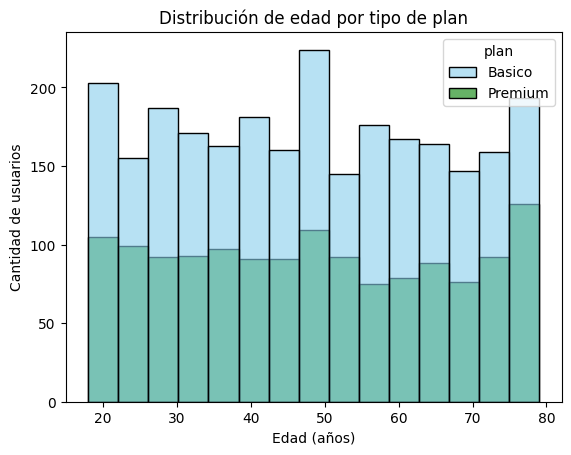

In [122]:
# Histograma para visualizar la edad (age)
sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=15,
    alpha=0.6
)
plt.title('Distribución de edad por tipo de plan')
plt.xlabel('Edad (años)')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 

- La distribución de edades es relativamente uniforme entre los 18 y 79 años, sin presentar un sesgo marcado hacia la derecha o la izquierda.

- El plan Básico registra una mayor cantidad de usuarios en casi todos los rangos de edad, lo que coincide con su mayor participación en la cartera de clientes (64.88 %).

- Ambos planes muestran patrones de edad similares. No se observa una concentración evidente en un grupo de edad específico que permita diferenciarlos claramente.

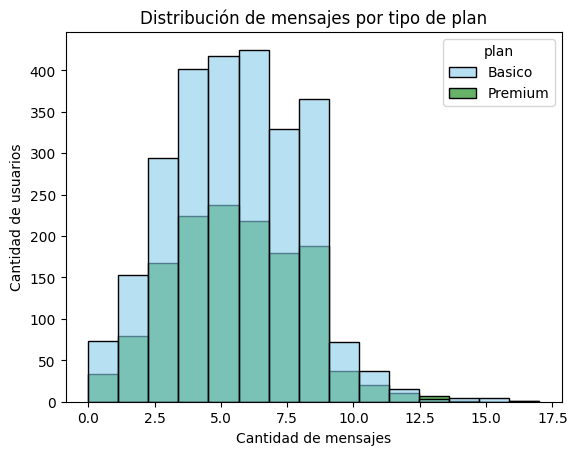

In [123]:
# Histograma para visualizar la cant_mensajes
sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=15,
    alpha=0.6
)
plt.title('Distribución de mensajes por tipo de plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights: 

- Al revisar la cantidad de mensajes, observo que la mayoría de los usuarios se concentra entre 3 y 9 mensajes, principalmente alrededor de 5 y 6. La distribución presenta un ligero sesgo hacia la derecha, debido a que son pocos los usuarios que registran cantidades más altas.

- Los planes Básico y Premium muestran un comportamiento bastante parecido. Aunque el plan Básico tiene más usuarios en casi todos los intervalos, esto no necesariamente significa que sus clientes envíen más mensajes, ya que también representa una mayor proporción del total de usuarios.

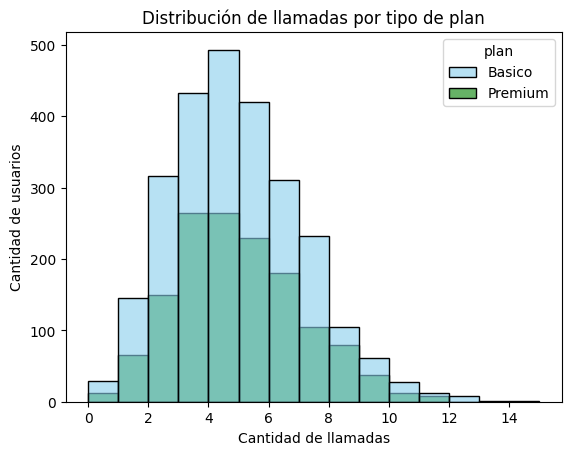

In [124]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=15,
    alpha=0.6
)
plt.title('Distribución de llamadas por tipo de plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- Al analizar la cantidad de llamadas, observo que la mayoría de los usuarios realiza entre 2 y 7 llamadas, con una mayor concentración alrededor de 4 y 5. La distribución presenta un sesgo hacia la derecha, ya que son pocos los usuarios que registran más de 10 llamadas.

- En ambos planes encuentro un comportamiento similar. Aunque el plan Básico concentra más usuarios, no se aprecia una diferencia importante en la forma de las distribuciones que permita afirmar que sus clientes realizan más llamadas que los del plan Premium.

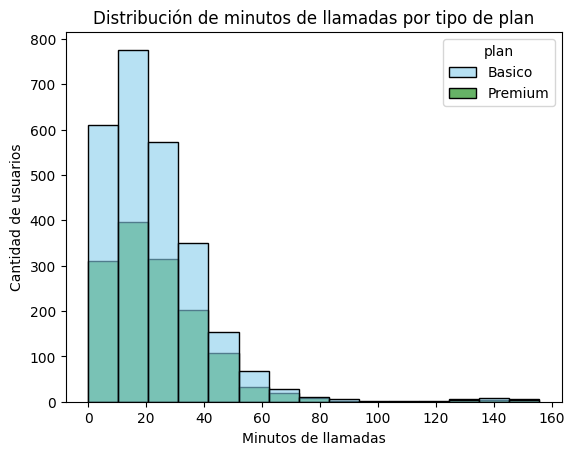

In [125]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=15,
    alpha=0.6
)
plt.title('Distribución de minutos de llamadas por tipo de plan')
plt.xlabel('Minutos de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights: 

- Al revisar los minutos acumulados en llamadas, observo que la mayor parte de los usuarios se concentra entre 0 y 40 minutos, principalmente alrededor de 10 a 20 minutos. La distribución presenta un sesgo marcado hacia la derecha, ya que conforme aumenta el tiempo de llamadas, disminuye la cantidad de usuarios.
- Los planes Básico y Premium mantienen un comportamiento similar, aunque el Básico registra más usuarios en los intervalos principales. También identifico algunos casos que superan los 100 minutos de llamadas. Considero importante revisarlos en el siguiente apartado para determinar si son consumos elevados válidos o posibles valores atípicos que requieran atención.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `cant_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.

- Después de crear los gráficos, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

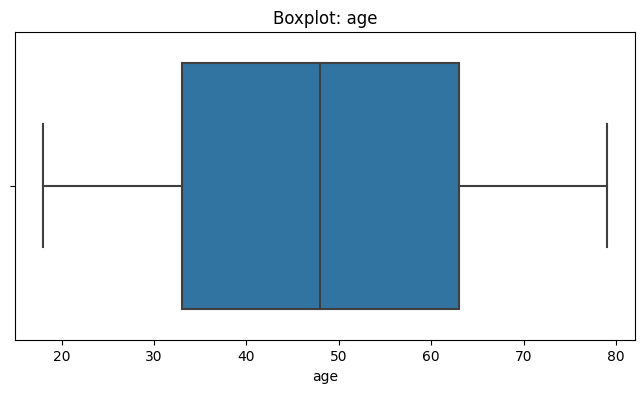

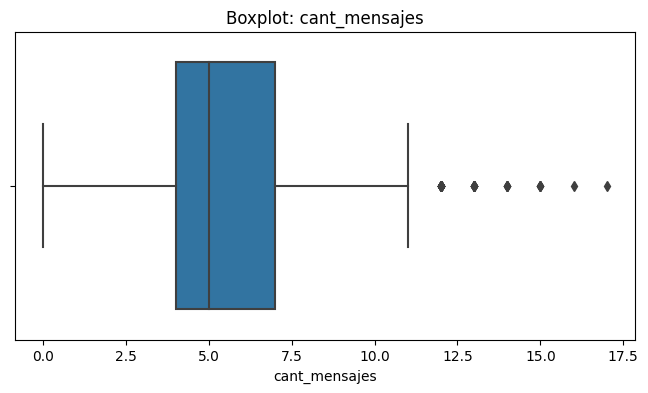

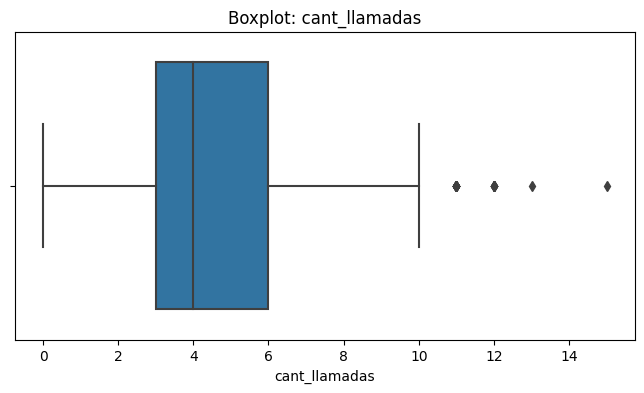

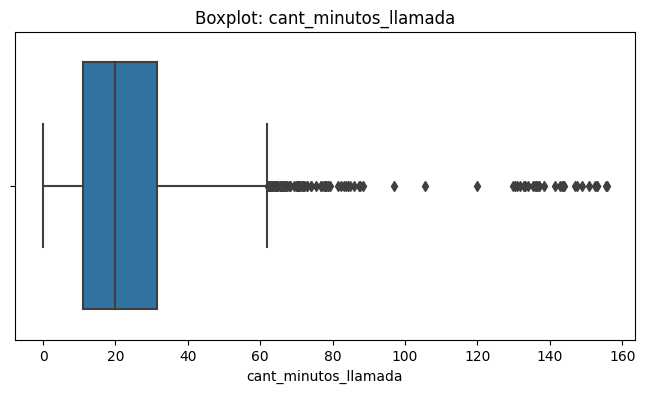

In [126]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()


💡Insights: 
- Edad: Al revisar el boxplot, no encuentro valores atípicos. Las edades se mantienen dentro de los límites esperados, por lo que no considero necesario realizar ajustes en esta variable.

- Cantidad de mensajes: Identifico algunos usuarios que registran 12 mensajes o más. Aunque estos valores se alejan del comportamiento habitual, no necesariamente representan errores, por lo que considero importante revisarlos antes de decidir si requieren algún tratamiento.

- Cantidad de llamadas: Observo valores atípicos a partir de 11 llamadas. Son casos poco frecuentes en comparación con la mayoría de los usuarios, pero podrían corresponder a un mayor uso del servicio.

- Minutos de llamadas: Esta variable presenta la mayor cantidad de valores atípicos, principalmente por encima de los 62 minutos. Algunos usuarios acumulan más de 100 minutos, por lo que será importante evaluar estos registros para determinar si son consumos válidos o posibles inconsistencias.

In [82]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR

    print(f'{col}: límite superior = {limite_superior:.2f}')




cant_mensajes: límite superior = 11.50
cant_llamadas: límite superior = 10.50
cant_minutos_llamada: límite superior = 61.86


In [83]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 

- cant_mensajes:Decido mantener los valores atípicos. El límite superior es de 11.50 mensajes y el máximo registrado es de 17. Aunque algunos usuarios envían más mensajes que el promedio, no encuentro evidencia suficiente para considerar estos registros como errores. Eliminarlos podría afectar el análisis del consumo real.
  
- cant_llamadas: También considero adecuado conservar estos valores. El límite superior calculado es de 10.50 llamadas y el máximo es de 15. Esta diferencia podría explicarse por usuarios que utilizan el servicio con mayor frecuencia, por lo que prefiero mantenerlos para no perder información sobre su comportamiento.


- cant_minutos_llamada: En esta variable observo una diferencia mayor, ya que el límite superior es de 61.86 minutos y el máximo alcanza 155.69. Por ahora decido conservar estos registros, aunque considero importante revisarlos posteriormente porque podrían influir en los resultados, especialmente en el promedio. Sin evidencia de que sean datos incorrectos, no encuentro justificación para eliminarlos.

---

## 🧩 Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [84]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]

grupos = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(
    condiciones,
    grupos,
    default='Alto uso'
)

# Evitar clasificar como Alto uso a usuarios sin datos
sin_datos = user_profile[['cant_llamadas', 'cant_mensajes']].isna().any(axis=1)
user_profile.loc[sin_datos, 'grupo_uso'] = pd.NA

In [85]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaT,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaT,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaT,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaT,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaT,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:** Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [86]:
# Crear columna grupo_edad
condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

grupos_edad = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(
    condiciones_edad,
    grupos_edad,
    default='Adulto Mayor'
)


In [87]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaT,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaT,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaT,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaT,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaT,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

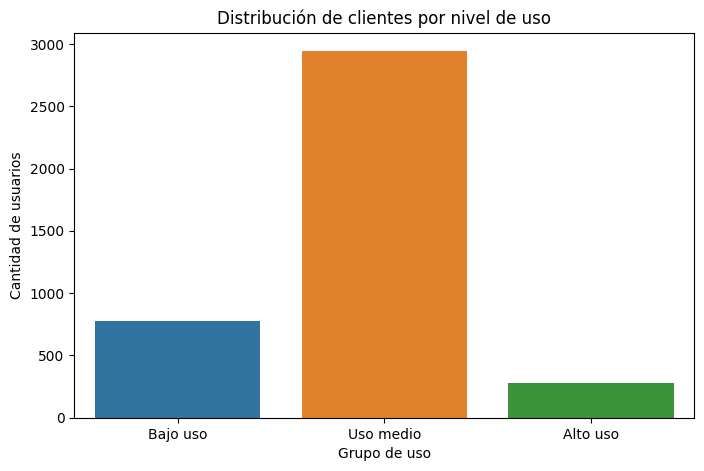

In [88]:
# Visualización de los segmentos por uso
plt.figure(figsize=(8, 5))

sns.countplot(
    data=user_profile,
    x='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso']
)

plt.title('Distribución de clientes por nivel de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')

plt.show()

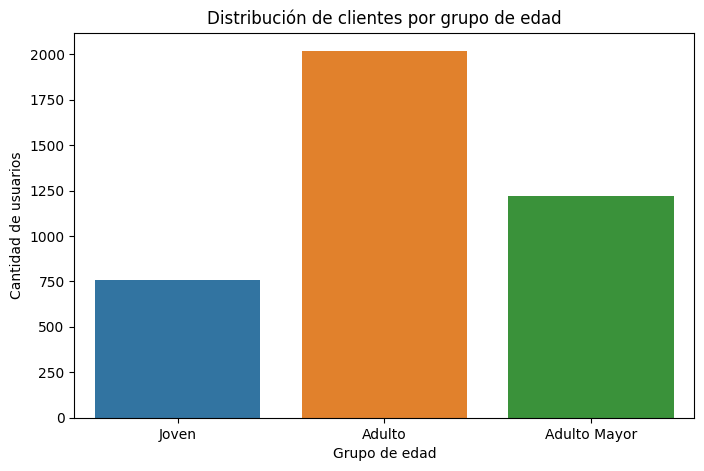

In [89]:
# Visualización de los segmentos por edad
plt.figure(figsize=(8, 5))

sns.countplot(
    data=user_profile,
    x='grupo_edad',
    order=['Joven', 'Adulto', 'Adulto Mayor']
)

plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')

plt.show()

In [90]:
# Revisión la relación entre edad y nivel de uso
pd.crosstab(
    user_profile['grupo_edad'],
    user_profile['grupo_uso'],
    normalize='index'
).mul(100).round(2)

grupo_uso,Alto uso,Bajo uso,Uso medio
grupo_edad,,,
Adulto,7.59,18.05,74.37
Adulto Mayor,6.06,21.03,72.91
Joven,6.71,20.66,72.63



---
## 🧩 Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 

- ¿Qué problemas tenían originalmente los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?

- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?


✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

#### 1. Problemas detectados en los datos

- Durante la revisión inicial de los datos identifiqué inconsistencias que podían afectar la precisión del análisis y que fue necesario revisar antes de estudiar el comportamiento de los clientes.

- Edades incorrectas: encontré registros con el valor -999, que no corresponde a una edad real. Para corregirlos utilicé la mediana calculada a partir de las edades válidas, evitando que estos valores alteraran los resultados estadísticos.

- Ciudades sin identificar: detecté 469 registros originalmente nulos y 96 con el símbolo `?`. En conjunto son 565 registros sin ciudad identificable, equivalentes al 14.13% de los 4,000 usuarios. Los símbolos `?` se transformaron en valores faltantes.

- Fechas de registro inconsistentes: identifiqué 40 registros con fechas de 2026, fuera del periodo histórico analizado. Estos casos representan el 1% de los usuarios y se marcaron como fechas faltantes para evitar interpretaciones incorrectas.

- Fechas de cancelación: fue necesario convertir los valores originales a un formato de fecha válido. Después de la transformación se identificaron 466 fechas de cancelación registradas y 3,534 usuarios sin fecha de cancelación.

- Registros de uso: se encontraron 50 eventos sin fecha válida, equivalentes al 0.125% de los 40,000 eventos. También se identificaron valores faltantes en duración y longitud, principalmente asociados al tipo de evento, ya que las llamadas y los mensajes requieren información diferente.

Estas revisiones permitieron mejorar la calidad de los datos y documentar las limitaciones que deben considerarse al interpretar los resultados.

#### 2. Segmentos de clientes por edad

Clasifiqué a los usuarios en tres grupos:

- **Joven:** menores de 30 años.
- **Adulto:** entre 30 y 59 años.
- **Adulto Mayor:** 60 años o más.

La distribución muestra que el grupo de Adultos es el más numeroso, seguido por Adultos Mayores y Jóvenes.

Al relacionar la edad con el nivel de consumo, observé los siguientes resultados:

| Grupo de edad | Bajo uso | Uso medio | Alto uso |
|---|---:|---:|---:|
| Joven | 20.66% | 72.63% | 6.71% |
| Adulto | 18.05% | 74.37% | 7.59% |
| Adulto Mayor | 21.03% | 72.91% | 6.06% |

Estos porcentajes corresponden a la distribución interna de cada grupo de edad.

El hallazgo principal es que el uso medio predomina en los tres grupos, con porcentajes superiores al 72%.

También identifiqué diferencias que pueden ser relevantes para el negocio. Los adultos tienen la mayor proporción de clientes de alto uso, mientras que los adultos mayores presentan la mayor proporción de clientes de bajo uso.

Esto indica que la edad permite reconocer algunas diferencias en el comportamiento, aunque no determina por sí sola el nivel de consumo.

#### 3. Segmentos por nivel de uso y valor potencial

Para analizar los hábitos de comunicación, clasifiqué a los usuarios según la cantidad de llamadas y mensajes registrados:

- Bajo uso: menos de 5 llamadas y menos de 5 mensajes.

- Uso medio: menos de 10 llamadas y menos de 10 mensajes, siempre que no cumplan las condiciones de bajo uso.

- Alto uso: usuarios que no cumplen las condiciones anteriores.

La gráfica de segmentación muestra que el uso medio concentra a la mayor parte de los clientes, seguido por el bajo uso y, finalmente, el alto uso.

Desde una perspectiva comercial, considero que existen dos segmentos prioritarios:

- Clientes de uso medio. Son el grupo más numeroso y representan una oportunidad importante para estrategias de retención, mejora de beneficios y satisfacción del cliente. Mantener una oferta adecuada para este segmento podría beneficiar a una proporción considerable de la base de usuarios.

- Clientes de alto uso. Aunque son menos numerosos, utilizan los servicios con mayor intensidad. Esto podría representar una oportunidad para ofrecer paquetes con mayores beneficios de llamadas o mensajes, especialmente entre los adultos, donde se observa una proporción ligeramente superior de alto consumo.

Sin embargo, es importante aclarar que un mayor consumo no significa necesariamente una mayor rentabilidad. Para identificar cuáles son los clientes que generan más ingresos sería necesario analizar información adicional sobre pagos, costos y permanencia.

Por lo tanto, estos grupos se consideran segmentos con valor comercial potencial, no segmentos cuya rentabilidad ya esté demostrada.

#### 4. Patrones de uso extremo (outliers)

Utilicé diagramas de caja y el método del rango intercuartílico (IQR) para identificar valores atípicos en las variables de edad, mensajes, llamadas y minutos de llamada.

Los resultados fueron los siguientes:

| Variable | Límite superior IQR | Valor máximo |
|---|---:|---:|
| Cantidad de mensajes | 11.50 | 17 |
| Cantidad de llamadas | 10.50 | 15 |
| Minutos de llamada | 61.86 | 155.69 |

En la variable edad no identifiqué valores atípicos mediante el diagrama de caja.

En cambio, encontré usuarios con cantidades de mensajes y llamadas superiores al comportamiento habitual.

La diferencia más importante aparece en los minutos de llamada, donde algunos clientes superan los 100 minutos y el máximo alcanza 155.69 minutos.

Decidí conservar estos valores porque no encontré evidencia suficiente para considerarlos errores. Es posible que representen usuarios con necesidades de comunicación mayores que las del resto.

Para ConnectaTel, estos resultados tienen dos implicaciones:

- **Oportunidad comercial:** permiten identificar usuarios que podrían necesitar planes con mayor capacidad o beneficios adicionales.

- **Precaución analítica:** los consumos extremos pueden elevar los promedios, por lo que conviene considerar también la mediana al describir el comportamiento habitual.

#### 5. Recomendaciones para ConnectaTel

A partir de los resultados obtenidos, propongo las siguientes acciones:

**1. Fortalecer los planes dirigidos al uso medio.**

Dado que este comportamiento predomina en todos los grupos de edad, recomiendo revisar si los planes actuales ofrecen una cantidad adecuada de llamadas y mensajes. También sería conveniente desarrollar estrategias de fidelización para este segmento.

**2. Evaluar planes para usuarios de alto consumo.**

Los usuarios con más llamadas, mensajes o minutos podrían beneficiarse de paquetes ampliados. Antes de crear una nueva oferta, sería necesario analizar su disposición de pago y la rentabilidad esperada.

**3. Explorar alternativas para clientes de bajo uso.**

Este segmento podría beneficiarse de planes sencillos o flexibles. La propuesta sería especialmente relevante para estudiar las necesidades de los adultos mayores, quienes presentan la proporción más alta de bajo consumo.

**4. Utilizar la segmentación para mejorar la retención.**

Recomiendo combinar los grupos de edad y consumo con las fechas de cancelación para investigar si existen patrones asociados al abandono del servicio. Esto permitiría diseñar acciones preventivas mejor orientadas.

**5. Fortalecer los controles de calidad de los datos.**

Es importante establecer validaciones para edades, ciudades, fechas y registros de uso. Contar con información consistente permitirá generar análisis más confiables y tomar mejores decisiones comerciales.

#### 6. Conclusión ejecutiva

El análisis permitió identificar que el consumo medio es el patrón predominante entre los clientes de ConnectaTel, independientemente de su grupo de edad.

También observé que los adultos presentan una proporción ligeramente mayor de alto consumo, mientras que los adultos mayores tienen una mayor participación relativa en el bajo consumo.

Los valores atípicos, especialmente en los minutos de llamada, muestran que existen clientes con necesidades superiores a las habituales. Por esta razón, decidí conservarlos y considerarlos una oportunidad de análisis comercial.

Mi recomendación principal es priorizar la retención y mejora de la experiencia de los usuarios de consumo medio, sin dejar de explorar ofertas diferenciadas para clientes de alto y bajo uso.

Finalmente, considero importante complementar estos resultados con información de ingresos, costos y cancelaciones antes de tomar decisiones definitivas sobre precios o rentabilidad. De esta manera, ConnectaTel podrá transformar los patrones identificados en estrategias comerciales mejor fundamentadas.



---

## 🧩 Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A: Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B: Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

**Enlace al repositorio público del proyecto:** https://github.com/luisrogelioaguilar1-cell/connectatel-analysis